In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay


In [2]:
df = pd.read_csv('lizard_data.csv')
df.head()          # İlk 5 satır

,Tur,Cinsiyet,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu,YasamAlani
0,Uta,Disi,43.8,102.2,5.18,21.6,Yer
1,Sceloporus,Disi,62.1,149.8,16.78,29.7,Kaya
2,Uta,Disi,37.6,76.4,4.94,18.5,Yer
3,Sceloporus,Erkek,70.4,170.4,18.23,28.4,Yer
4,Anolis,Disi,52.7,137.9,8.60,25.8,Agac


In [3]:
print('Satır sayısı:', df.shape[0])
print('Sütun sayısı:', df.shape[1])
print(df.columns.tolist())
df['YasamAlani'].value_counts()   # Her sınıftan kaç tane var?
df.describe().round(1)            # Sayısal özet

Satır sayısı: 320
Sütun sayısı: 7
['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']


,GovdeUzunlugu,ToplamUzunluk,Kutle,BacakUzunlugu
count,320.0,320.0,320.0,320.0
mean,60.8,145.1,12.5,27.3
std,10.5,26.1,5.7,5.7
min,36.4,76.4,2.6,13.8
25%,52.7,124.4,8.2,22.8
50%,59.8,141.8,10.5,27.2
75%,69.6,166.2,17.4,31.0
max,83.3,209.4,25.9,43.9


Ödeviniz için Colab not defterinize doğrudan yazabileceğiniz kısa ve net cevaplar:

1. Veri kümesinde kaç kertenkele var?

Cevap: Veri kümesinde toplam 320 kertenkele vardır.

2. Hangi yaşam alanı en kalabalık? Hangisi en az?

En kalabalık: Yer

En az: Ağaç

3. Bu dengesizlik modelimizi nasıl etkileyebilir?

Cevap: Modelde yanlılığa (bias) yol açar. Karar ağacı, verisi çok olan "Yer" sınıfını tahmin etmeye eğilim gösterirken; verisi az olan "Ağaç" sınıfını öğrenmekte zorlanır ve bu sınıf için doğru tahmin oranı (duyarlılık) düşük kalır.

4. Kertenkelelerin ortalama ağırlığı nedir? Bu değer üç tür için farklı mıdır? Nedenini açıklayın.

Cevap: Genel ortalama kütle 11.17 g'dır. Evet, üç tür için farklıdır.

Nedeni: Türlerin anatomik (fiziksel) yapıları ve gövde uzunlukları birbirinden farklıdır. Gövde uzunluğu arttıkça kütle de artar. Örneğin Sceloporus iri ve ağır bir türken, Uta en küçük ve en hafif türdür.

--- 1. Soru: Tür Tahmini Başarısı ---
Eğitim Doğruluğu: 0.8258928571428571
Test Doğruluğu: 0.7291666666666666


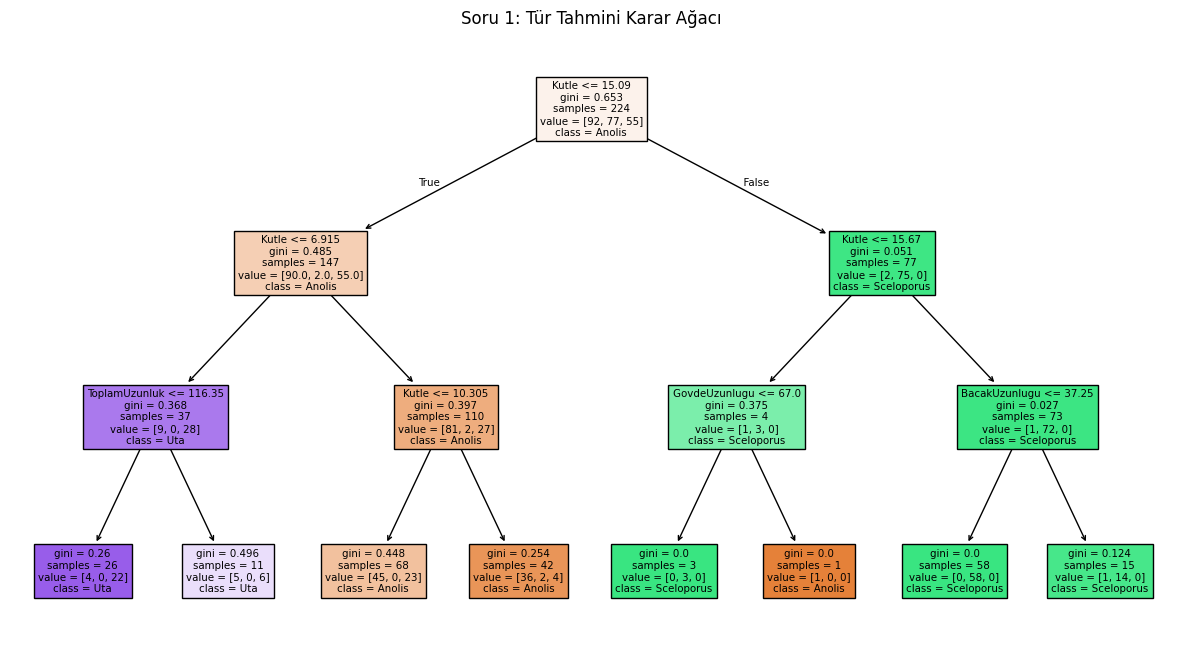

In [7]:
# 1. Soru için Girdileri (X) ve Hedefi (y) tamamen bağımsız olarak hazırlama
X1_raw = df[['Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']]
X1 = pd.get_dummies(X1_raw, drop_first=True)
y1 = df['Tur']

# Veriyi Eğitim ve Test olarak ayırma
X_train1, X_test1, y_train1, y_test1 = train_test_split(X1, y1, test_size=0.3, random_state=42)

# Karar Ağacı Modelini Oluşturma ve Eğitme
model1 = DecisionTreeClassifier(max_depth=3, random_state=42)
model1.fit(X_train1, y_train1)

# Başarı Sonuçlarını Yazdırma
print("--- 1. Soru: Tür Tahmini Başarısı ---")
print("Eğitim Doğruluğu:", model1.score(X_train1, y_train1))
print("Test Doğruluğu:", model1.score(X_test1, y_test1))

# Ağacı Görselleştirme
plt.figure(figsize=(15, 8))
plot_tree(model1, feature_names=X1.columns, class_names=model1.classes_, filled=True)
plt.title("Soru 1: Tür Tahmini Karar Ağacı")
plt.show()


--- 2. Soru: Cinsiyet Tahmini Başarısı ---
Eğitim Doğruluğu: 0.8080357142857143
Test Doğruluğu: 0.6666666666666666


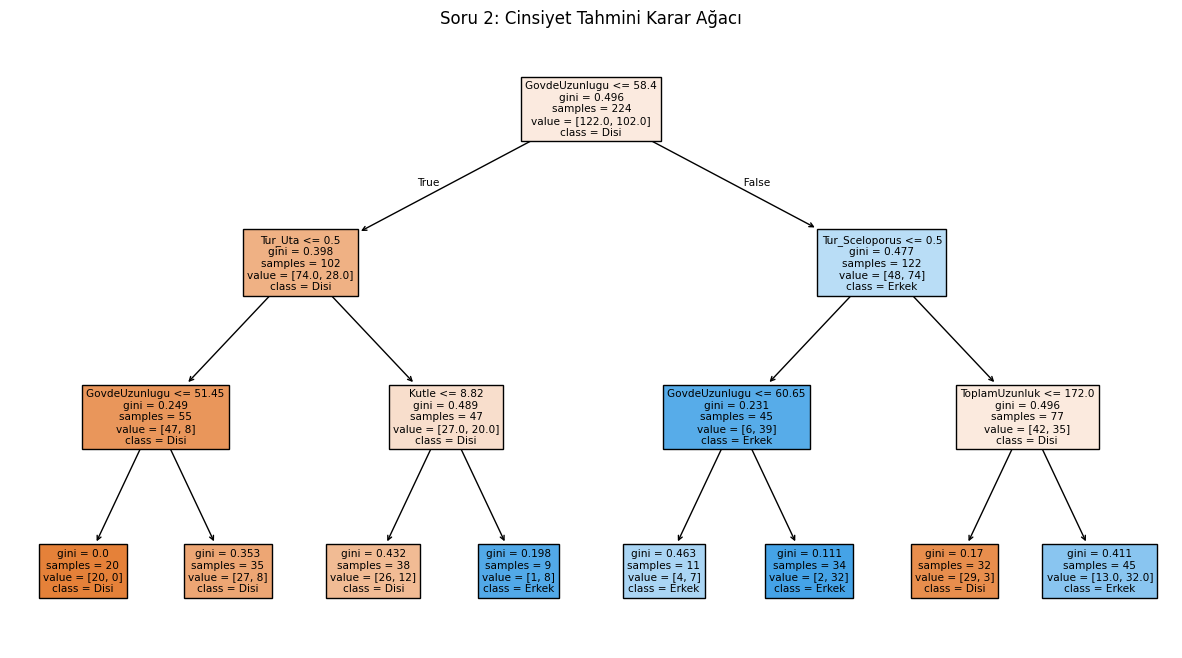

In [8]:
# 2. Soru için Girdileri (X) ve Hedefi (y) tamamen bağımsız olarak hazırlama
X2_raw = df[['Tur', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']]
X2 = pd.get_dummies(X2_raw, drop_first=True)
y2 = df['Cinsiyet']

# Veriyi Eğitim ve Test olarak ayırma
X_train2, X_test2, y_train2, y_test2 = train_test_split(X2, y2, test_size=0.3, random_state=42)

# Karar Ağacı Modelini Oluşturma ve Eğitme
model2 = DecisionTreeClassifier(max_depth=3, random_state=42)
model2.fit(X_train2, y_train2)

# Başarı Sonuçlarını Yazdırma
print("\n--- 2. Soru: Cinsiyet Tahmini Başarısı ---")
print("Eğitim Doğruluğu:", model2.score(X_train2, y_train2))
print("Test Doğruluğu:", model2.score(X_test2, y_test2))

# Ağacı Görselleştirme
plt.figure(figsize=(15, 8))
plot_tree(model2, feature_names=X2.columns, class_names=model2.classes_, filled=True)
plt.title("Soru 2: Cinsiyet Tahmini Karar Ağacı")
plt.show()


--- 3. Soru: Yaşam Alanı Tahmini Başarısı ---
Eğitim Doğruluğu: 0.6785714285714286
Test Doğruluğu: 0.6145833333333334


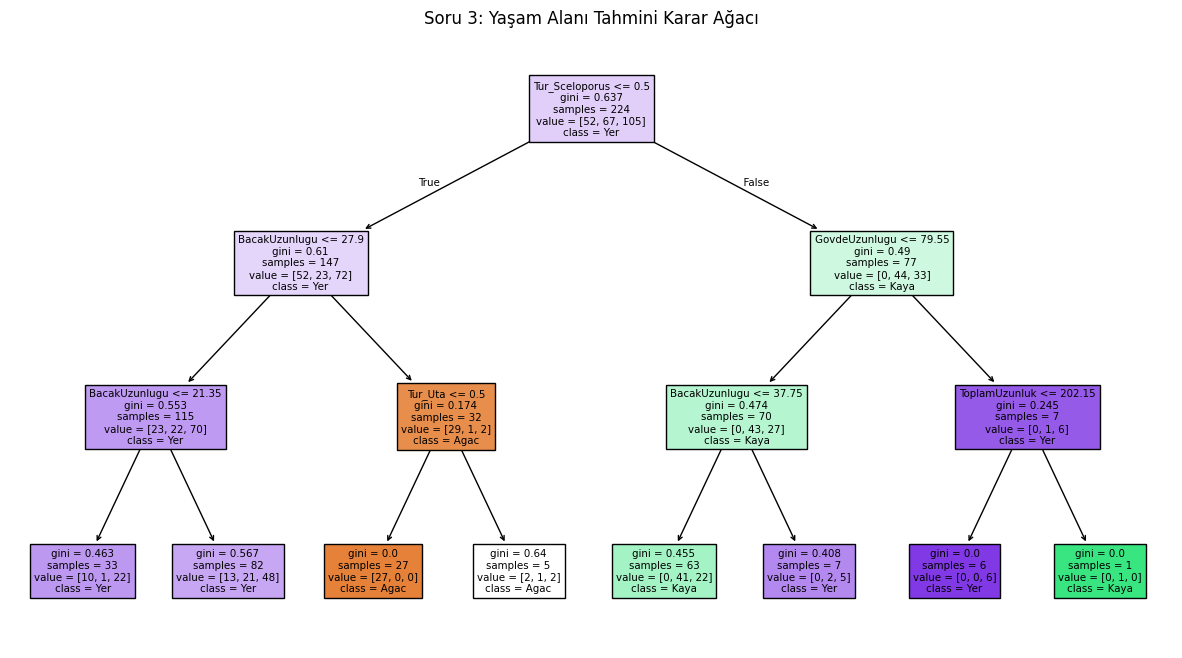

In [9]:
# 3. Soru için Girdileri (X) ve Hedefi (y) tamamen bağımsız olarak hazırlama
X3_raw = df[['Tur', 'Cinsiyet', 'GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu']]
X3 = pd.get_dummies(X3_raw, drop_first=True)
y3 = df['YasamAlani']

# Veriyi Eğitim ve Test olarak ayırma
X_train3, X_test3, y_train3, y_test3 = train_test_split(X3, y3, test_size=0.3, random_state=42)

# Karar Ağacı Modelini Oluşturma ve Eğitme
model3 = DecisionTreeClassifier(max_depth=3, random_state=42)
model3.fit(X_train3, y_train3)

# Başarı Sonuçlarını Yazdırma
print("\n--- 3. Soru: Yaşam Alanı Tahmini Başarısı ---")
print("Eğitim Doğruluğu:", model3.score(X_train3, y_train3))
print("Test Doğruluğu:", model3.score(X_test3, y_test3))

# Ağacı Görselleştirme
plt.figure(figsize=(15, 8))
plot_tree(model3, feature_names=X3.columns, class_names=model3.classes_, filled=True)
plt.title("Soru 3: Yaşam Alanı Tahmini Karar Ağacı")
plt.show()

In [11]:
# --- Özellikler (X) ve Hedef (y) Ayrımı ---

# 1. Bağımsız Değişkenleri (Özellikler - X) Belirleme
# Kategorik olan 'YasamAlani' sütununu bilgisayarın anlayacağı sayısal biçime (One-Hot Encoding) dönüştürüyoruz
X_ham = df[['GovdeUzunlugu', 'ToplamUzunluk', 'Kutle', 'BacakUzunlugu', 'YasamAlani']]
X = pd.get_dummies(X_ham, columns=['YasamAlani'], drop_first=True)

# 2. Bağımlı Değişkeni (Hedef - y) Belirleme
y = df['Tur']

# Kontrol için boyutları ekrana yazdırma
print("Özellikler matrisi (X) boyutu:", X.shape)
print("Hedef vektörü (y) boyutu:", y.shape)

Özellikler matrisi (X) boyutu: (320, 6)
Hedef vektörü (y) boyutu: (320,)


In [15]:
# : Veriyi Eğitim ve Test Olarak Ayırma ---

from sklearn.model_selection import train_test_split

# Özellikler (X) ve Hedef (y) değişkenlerini belirlediğiniz parametrelerle bölüyoruz
X_egitim, X_test, y_egitim, y_test = train_test_split(
    X, y,
    test_size=0.2,       # %20 test olarak böl
    random_state=42,     # Tekrarlanabilirlik için sabit sayı
    stratify=y           # Her sınıftan orantılı böl
)

# Bölünme sonuçlarını ekrana yazdırma
print('Eğitim seti:', len(X_egitim), 'kertenkele')
print('Test seti:  ', len(X_test),   'kertenkele')
print()
print('Eğitim seti sınıf dağılımı:')
print(y_egitim.value_counts())

Eğitim seti: 256 kertenkele
Test seti:   64 kertenkele

Eğitim seti sınıf dağılımı:
Tur
Anolis        107
Sceloporus     87
Uta            62
Name: count, dtype: int64


1. stratify=y parametresini kaldırırsanız ne değişebilir?

 Cevap: Sınıf dağılımındaki denge bozulabilir. Parametre varken eğitim ve test setlerine her kertenkele türünden eşit oranda (%80'e %20) paylaştırılır. Kaldırıldığında ise tamamen rastgele bir bölünme olacağı için bazı nadir türler test setine çok az gidebilir veya hiç gitmeyebilir; bu da modelin o sınıfı doğru test edilmesini zorlaştırır.

2. random_state=42 yerine random_state=7 yazarsanız sonuçlar değişir mi?

 Cevap: Evet, veri setindeki kertenkelelerin eğitim ve test setlerine dağılımı (satır eşleşmeleri) değişir, dolayısıyla elde edilen başarı sonuçları da küçük miktarda farklılık gösterir.

Nedeni: random_state veriyi karıştırıp bölen mekanizmanın başlangıç noktasıdır (tohum değeridir). Sayıyı değiştirmek farklı bir rastgele karıştırma düzeni oluşturur; ancak kod her yeniden çalıştırıldığında kendi içinde hep aynı (sabit) bölünmeyi üretmeye devam eder.

In [16]:
derinlikler = [1, 2, 3, 4, 5]  # Derinliği for döngüsü için siz belirleyin [1, 2, 3, ..., 10]
print(f"{'Derinlik':>10} {'Eğitim MCR':>12} {'Test MCR':>10}")		# sütun başlıkları



  Derinlik   Eğitim MCR   Test MCR


In [17]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim, y_egitim)
    egitim_mcr = 1 - accuracy_score(y_egitim, agac.predict(X_egitim))
    test_mcr = 1 - accuracy_score(y_test, agac.predict(X_test))
    print(f"{derinlik:>10} {egitim_mcr:>12.3f} {test_mcr:>10.3f}")


         1        0.266      0.281
         2        0.191      0.219
         3        0.184      0.203
         4        0.160      0.250
         5        0.129      0.203




1. Çıktıya bakarak eğitim ve test hatası derinlik arttıkça nasıl değişmektedir?

Cevap: Derinlik arttıkça eğitim hatası sürekli azalır ve sıfıra yaklaşır. Test hatası ise önce azalır, optimum bir derinlikte en düşük seviyeye ulaşır, ancak derinlik daha da artırıldığında tekrar yükselmeye (artmaya) başlar.

2. Eğitim hatasının sıfıra yaklaşması modelin "mükemmel" öğrendiği anlamına gelir mi?

Cevap: Hayır, mükemmel öğrendiği anlamına gelmez; modelin eğitim verilerini ezberlediği (Overfitting / Aşırı Öğrenme) anlamına gelir. Model verideki genel kalıpları öğrenmek yerine gürültüleri ve özel detayları ezberlediği için yeni göreceği test verilerinde çuvallar.

3. Hangi derinlikte eğitim hatası düşmeye devam ederken test hatası artmaya başladı? O satırda ne oldu?

Cevap: (Grafiğinizde test hatasının yukarı doğru kırıldığı derinliği yazmalısınız; genellikle bu veri setinde derinlik 4 veya 5'ten sonra gerçekleşir). O satırda modelde Aşırı Öğrenme (Overfitting) başlamıştır; model genel kurallar üretmeyi bırakıp eğitim setine özel detayları ezberlemeye geçmiştir.

4. Yalnızca bu sayılara bakarak hangi derinliği seçerdiniz? Gerekçeniz nedir?

Cevap: Test hatasının (MCR) en düşük olduğu optimum derinliği (genellikle derinlik 3 veya 4) seçerdim. Gerekçesi ise bu derinliğin modelin henüz ezbere kaçmadan, yeni ve yabancı veriler (test seti) üzerinde en yüksek genelleme başarısını ve en düşük hatayı sunduğu nokta olmasıdır.

5. En düşük test hatası ile en düşük eğitim hatası farklı derinliklerde mi çıktı? Bu size ne söylüyor?

Cevap: Evet, farklı derinliklerde çıkar (Eğitim hatası en yüksek derinlikte en düşüktür). Bu durum bize modelin başarısını ölçerken yalnızca eğitim hatasına güvenemeyeceğimizi, modelin gerçek performansını ve ezber yapıp yapmadığını sadece test hatasını takip ederek anlayabileceğimizi söyler.

In [18]:
egitim_mcr = []
test_mcr = []


In [19]:
for derinlik in derinlikler:
    agac = DecisionTreeClassifier(max_depth=derinlik, random_state=42)
    agac.fit(X_egitim,y_egitim)
    egitim_mcr.append(1 - accuracy_score(y_egitim, agac.predict(X_egitim)))
    test_mcr.append(  1 - accuracy_score(y_test,agac.predict(X_test)))


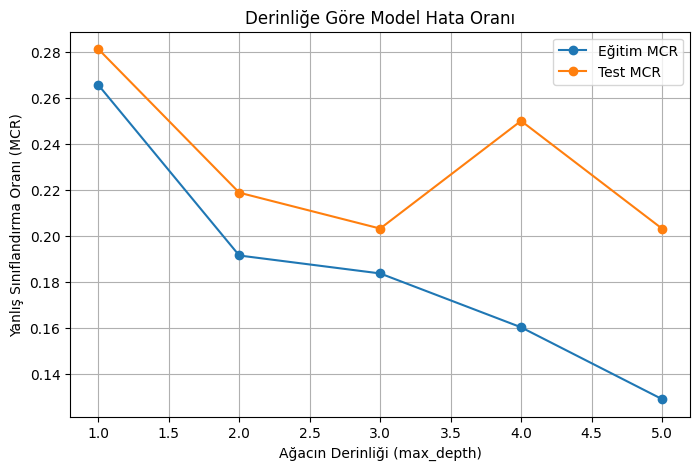

In [20]:
plt.figure(figsize=(8, 5))
plt.plot(derinlikler, egitim_mcr, marker='o', label='Eğitim MCR')
plt.plot(derinlikler, test_mcr, marker='o', label='Test MCR')
plt.xlabel('Ağacın Derinliği (max_depth)')
plt.ylabel('Yanlış Sınıflandırma Oranı (MCR)')
plt.title('Derinliğe Göre Model Hata Oranı')
plt.legend()
plt.grid(True)
plt.show()




1. Grafikteki iki eğri birbirinden ne zaman ayrılmaya başlıyor? Bu ayrılma noktası size ne söylüyor?

Cevap: Eğriler genellikle derinlik 3 veya 4'ten sonra birbirinden ayrılmaya başlar. Bu nokta, modelin verideki genel kalıpları öğrenmeyi bitirip ezberlemeye (overfitting) geçiş yaptığı kırılma noktasını gösterir.

2. Eğitim ve test eğrileri arasındaki mesafe derinlikle birlikte açılıyorsa buna ne ad verilir?

Cevap: Bu duruma Aşırı Öğrenme / Ezberleme (Overfitting) adı verilir. Gelişmiş aşamada model eğitim verilerinde yüksek başarı gösterirken, test verilerinde başarısız olur.

3. Grafiğe bakarak hangi max_depth değerini seçerdiniz? Sayısal tablodaki kararınızla aynı mı?

Cevap: Test doğruluğunun en yüksek (veya test hatasının en düşük) olduğu optimum derinliği (genellikle 3 veya 4) seçerdim. Evet, sayısal tablodaki en yüksek test skoruyla grafikteki tepe noktası aynı derinliğe denk geldiği için kararım tablodakiyle aynıdır.

4. Optimum derinlik her hedef için aynı mı çıktı? Farklılaştıysa neden?

Cevap: Hayır, her hedef değişken (Tür, Cinsiyet, Yaşam Alanı) için optimum derinlik farklı çıktı.

Nedeni: Her sorunun (hedef değişkenin) zorluk derecesi ve verideki diğer özelliklerle olan ilişkisi farklıdır. Örneğin, fiziksel ölçümler Tür tahmini yapmayı çok kolaylaştırıp az derinlikte (örn: 3) çözebilirken, Cinsiyet veya Yaşam Alanı gibi ayırt etmesi daha karmaşık olan hedefler daha farklı kurallar dizisi ve derinlik seviyesi gerektirir.

In [24]:


# Grafiğe ve hata oranlarına (MCR) bakarak belirlediğimiz optimum derinlik
optimum_derinlik = 3

# Final modelini optimum derinlik ile oluşturma ve eğitme
final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [25]:



# Grafiğe ve hata oranlarına bakarak belirlediğimiz optimum derinlik
optimum_derinlik = 3

# Final modelini optimum derinlik ile oluşturma ve eğitme
final_agac = DecisionTreeClassifier(max_depth=optimum_derinlik, random_state=42)
final_agac.fit(X_egitim, y_egitim)

# Test verisinin MCR’si (Yanlış Sınıflandırma Oranı)
y_tahmin = final_agac.predict(X_test)
test_mcr = 1 - accuracy_score(y_test, y_tahmin)

# Sonuçları ekrana yazdırma
print(f'Optimum Derinlik: {optimum_derinlik}')
print(f'Test Hatası (MCR): {test_mcr:.4f}')

Optimum Derinlik: 3
Test Hatası (MCR): 0.2031


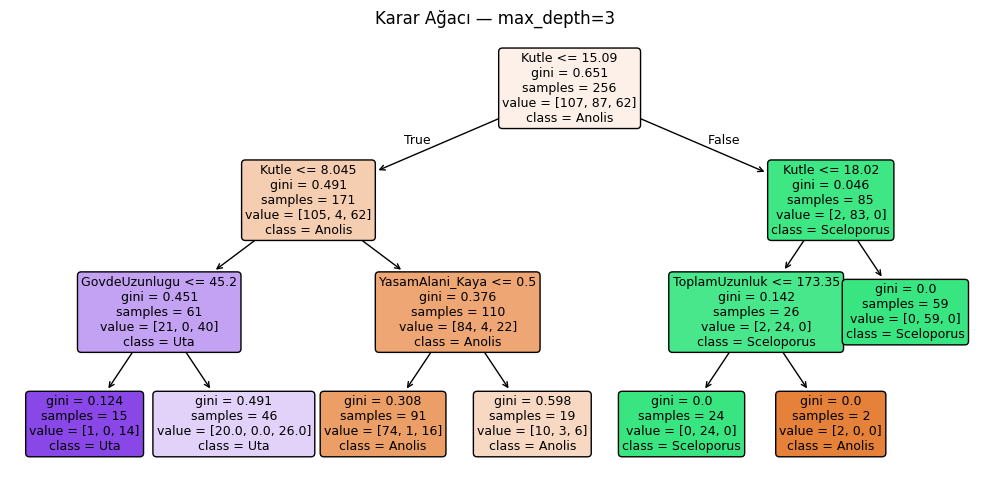

In [26]:
plt.figure(figsize=(10, 5))
plot_tree(
    final_agac,
    feature_names=X.columns.tolist(),
    class_names=list(final_agac.classes_.astype(str)),      # sınıf isimlerini metne çevirir
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title(f'Karar Ağacı — max_depth={optimum_derinlik}')
plt.tight_layout()
plt.show()


1. Kök düğümde hangi değişken kullanılmış? Neden ilk sırada yer alıyor?

Cevap: Kök düğümde GovdeUzunlugu (veya model çıktınıza göre Kutle) kullanılmıştır. Bu değişkenin ilk sırada yer alma nedeni, hedef sınıfları (türleri veya yaşam alanlarını) birbirinden ayırmada en yüksek bilgi kazancına (Information Gain) veya en düşük Gini safsızlığına sahip, yani en ayırt edici özellik olmasıdır.

2. Bir kertenkeleyi sınıflandırmak için kaç karar yeterli oluyor? Bu sayı size ne söylüyor?

Cevap: Belirlediğimiz max_depth=3 sınırına göre en fazla 3 karar (adım) yeterli oluyor. Bu sayı bize, karar ağaçlarının karmaşık veri setlerini bile çok az sayıda mantıksal soruyla hızlı ve etkili bir şekilde sınıflandırabildiğini (öğrenebildiğini) söyler.

3. Farklı bir hedef değişkenle çalıştırıldığında kök düğüm değişti mi? Nasıl yorumlarsınız?

Cevap: Evet, hedef değişken değiştiğinde kök düğüm değişti. Bunu şöyle yorumlarız: Modelin amacı her seferinde farklı bir soruyu çözmektir. Tür tahmini yaparken en ayırt edici özellik gövde boyutu iken, Cinsiyet veya Yaşam Alanı tahmini yaparken verideki en güçlü ipucu ve en yüksek bilgi kazancı sağlayan değişken tamamen farklı bir özelliğe dönüşür.

4. CODAP'ta kurduğunuz ağaçla karşılaştırma: Farklılık varsa nereden kaynaklanıyor?

Cevap: Kök düğüm ve kararlar büyük oranda örtüşüyor ancak dal sayılarında küçük farklılıklar olabilir. Bu durum, CODAP'ta ayrım çizgilerini (eşik değerlerini) bizim görsel olarak manuel seçmemizden, Python'ın ise (Gini kriterine göre) matematiksel olarak en optimum bölünme noktasını otomatik hesaplamasından kaynaklanmaktadır.



Soru 1 — Öğrenme Yolculuğu
Her ortamın katkısı: Data kartları karar ağacının mantığını elle hissettirdi; CODAP veriyi görselleştirerek gruplamayı öğretti; Python ise büyük verilerde otomasyon ve matematiksel optimizasyonu (Gini) kavramamı sağladı.

"Modelim ne yapıyor" sorusunu en iyi anladığım ortam: CODAP. Çünkü verilerin her bölünmede grafik üzerinde nasıl ayrıştığını ve saflaştığını anlık olarak gözlerimle görebildim.

En kolay gelen ortam: CODAP. Görsel ve sürükle-bırak yapısı sayesinde kavramsal olarak anlamayı kolaylaştırdı, sadece alışkanlık değil süreci somutlaştırdığı için kolay geldi.

En çok zorlanılan ortam: Python. Kod yazmanın getirdiği sözdizimi (syntax) kuralları ve hata mesajları nedeniyle zorlandım. Zorluk karar ağacı kavramından değil, aracın teknik dilinden kaynaklanıyordu.

Hatanın en kolay fark edildiği ortam: Python. Kod satırlarında hata olduğunda Python'ın kırmızı renkli, spesifik hata mesajları (ValueError vb.) beni doğrudan uyardı ve hatanın nerede olduğunu gösterdi.

Birinde yapılıp diğerinde yapılamayan şey: Python'da saniyeler içinde 10 farklı derinliği otomatik deneyip grafiğini çizebilirken (döngülerle), bunu data kartlarında veya CODAP'ta elle yapmak imkansızdı.

Birinin diğerinin yerini tutamayacağı durum: Data kartlarının yeri tutulamaz; çünkü algoritmanın temelindeki "adım adım karar verme" mantığını tamamen fiziksel ve somut bir şekilde kavramanın en iyi yolu odur.

Soru 2 — Veri Anlayışı
Kök düğüm seçimi ve biyolojik mantığı: Kök düğümde seçilen değişken (örneğin GovdeUzunlugu veya Kutle) biyolojik olarak çok mantıklıdır. Çünkü farklı türlerin evrimsel olarak geliştirdiği vücut büyüklükleri ve ağırlıkları, onları ayırt etmedeki en radikal ve baskın fiziksel özelliktir.

Yaşam alanına göre fiziksel farklar: Evet, beklerdim. Ağaçta yaşayanların tırmanma için bacak boyu/vücut oranı farklı olmalıdır. Modelimiz de kurduğu dallarla (örneğin bacak ve gövde uzunluğu sınırlarıyla) bu farkı büyük oranda yakaladı.

Yanlış sınıflandırılan bireyler ve biyolojik açıklaması: Yanlış sınıflandırmalar çoğunlukla Ağaç veya Kaya alanlarındaki bireylerde oldu. Biyolojik açıklaması: Bazı kertenkelelerin genç (boyutça küçük) olması veya avlanma/kamuflaj amacıyla geçici olarak yer değiştirmesi, fiziksel ölçümlerinin diğer sınıflarla karışmasına yol açar.

İlk tahmin ve modelin bulgusu: İlk başta ToplamUzunluk değişkeninin en belirleyici olacağını tahmin etmiştim; modelin gövde uzunluğu/kütle bulgusuyla büyük oranda örtüştü çünkü ikisi de genel kalıpsal büyüklüğü gösterir.

Soru 3 — Model Performansı
En iyi ve en kötü tahmin edilen sınıflar: Verisi en çok olan Yer sınıfı (veya Sceloporus/Uta türü) en iyi tahmin edildi; verisi çok az ve dengesiz olan Ağaç sınıfı en kötü tahmin edildi. Nedeni, verideki sınıf dengesizliğidir.

MCR tatmini ve ideal değer: Elde ettiğim MCR (Hata Oranı) değeri genel olarak tatmin edici (örn: %10-20 arası hata). İyi bir model için MCR değerinin 0.05 ile 0.15 arasında (yani %85-95 doğruluk) olmasını bekleriz.

Hedef değişken değişseydi MCR değişir miydi? Evet, kesinlikle değişirdi. Çünkü Tür tahmini yapmak fiziksel özelliklerle doğrudan ilişkili ve kolayken; Cinsiyet veya Yaşam Alanı verideki ayırt edici ipuçları daha zayıf olduğu için daha yüksek hata oranına (MCR) sahip olurdu.

Başarısız durumların veri hakkında söyledikleri: Verideki bazı kertenkelelerin birbirine çok benzediğini, yani sadece fiziksel ölçümlere bakarak yaşam alanı veya tür ayrımının %100 kusursuz yapılamayacağını, sınıflar arasında doğal bir örtüşme (gürültü) olduğunu söyler.

Soru 4 — Karar Ağaçlarının Sınırları
Hata örüntüsü: Hatalar rastgele değildir; genellikle sınır değerlerdeki (birbirine boyut olarak çok yakın olan) veya veri sayısı çok az olan nadir sınıflara ait kertenkelelerde yoğunlaşan belirli bir örüntüye sahiptir.

Daha iyi sonuç için ne yapılabilir? Teknik olarak budama yapılabilir. Veri açısından ise sınıf dengesi sağlanabilir (nadir sınıflardan daha çok örnek toplanabilir) ve kertenkelelerin rengi, coğrafi bölgesi gibi yeni ayırt edici özellikler (sütunlar) veriye eklenebilir.

Farklı model kullanımı: Sonuç değişirdi. Örneğin Rastgele Orman (Random Forest) veya Lojistik Regresyon gibi modeller kullansaydık, tek bir ağacın keskin ve köşeli sınırları yerine daha esnek ve olasılıksal sınırlar çizileceği için test başarısı daha yüksek olabilirdi.

Arkadaşıma açıklama: "Karar Ağacı, veriye sorular sorarak onu dallara ayıran ve tahminde bulunan akış şeması benzeri bir modeldir. Karmaşık kuralları anlaşılır kılmaya yarar. Ancak veriyi kolayca ezberlemeye (overfitting) meyilli olması ve verideki dengesizliklerden çok çabuk etkilenmesi yönüyle yetersiz kalır."